# MINGGU 13 — TUNING MODEL 2: ADVANCED (XGBOOST + SVD/SPARSE + FITUR GAYA PENULISAN)

**Mata Kuliah:** Data Science (Semester 5)  
**Proyek:** Analisis Klasifikasi Ujaran Kebencian pada Informasi Pemerintahan Indonesia di Media Sosial Menggunakan Machine Learning dan Deep Learning  
**Keterkaitan SDG:** **SDG 16** (*Peace, Justice and Strong Institutions*) — Target 16.10 & 16.7  
**PIC / Anggota 2:** Muhammad Adam Al-Kidri (244311050) — *Lead Tuning Advanced ML & Kontrol Overfitting*  
**Kolaborator / Anggota 1:** Ardhana Syah Hidayat (244311037)  

---

### Latar Belakang & Sasaran Analisis:
Pada evaluasi awal Minggu 3, model Advanced XGBoost (`82,22%`) mengalami ketertinggalan performa terhadap Baseline Logistic Regression (`84,14%`). Investigasi Bab 6.2 mengidentifikasi tiga kelemahan mendasar:
1. **Information Bottleneck pada TruncatedSVD:** Penggunaan 100 komponen hanya merangkum **23,45%** varians TF-IDF sehingga detail leksikal halus yang membedakan ujaran kebencian implisit dan kritik wajar banyak terbuang.
2. **Ketiadaan Regularisasi & Early Stopping:** Pelatihan awal menggunakan 100 pohon dengan parameter default tanpa mekanisme penghentian dini, menyebabkan model rentan menghafal kebisingan data latih.
3. **Pencarian Hiperparameter yang Belum Terstruktur:** Kedalaman pohon (`max_depth`), laju pembelajaran (`learning_rate`), dan subsampling belum dioptimasi secara sistematis melalui validasi silang.

### Tujuan Notebook Ini:
1. **Eksperimen Representasi Fitur:** Menguji perbaikan kapasitas representasi melalui **Skenario A** (menambah TruncatedSVD ke 200 dan 300 komponen + 6 fitur gaya penulisan) dan **Skenario B** (TF-IDF *sparse* langsung + 6 fitur gaya penulisan tanpa kompresi SVD) untuk memilih representasi terbaik.
2. **Hyperparameter Tuning Sistematis:** Menjalankan `RandomizedSearchCV` dengan **5-Fold Stratified Cross-Validation** pada `train.csv` (9.105 baris) dengan ruang pencarian 8 hiperparameter reguler.
3. **Implementasi Kontrol Overfitting (Bab 6.2.5):** Menerapkan *Early Stopping* (`early_stopping_rounds=20`), menganalisis kurva belajar (*Train Log-Loss vs Validation Log-Loss*), dan mengukur *gap* generalisasi antara data latih dan validasi.
4. **Optimasi Decision Threshold ($\tau$):** Menguji variasi ambang probabilitas $\tau \in [0.30, 0.70]$ pada Validation Set guna memenuhi target etika SDG 16 (**Precision Kelas 1 $\ge 85\%$**).
5. **Penyimpanan Metrik & Integritas Data:** Menyimpan seluruh artefak evaluasi ke `results/advanced_tuned_val_metrics.json` dan memperbarui `results/metrics_summary.csv` dengan mematuhi protokol **zero test leakage** (`test.csv` tetap disegel).

In [1]:
import time
import json
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

# Styling grafik
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
SEED = 42

current_dir = Path.cwd()
root_dir = current_dir if (current_dir / 'data').exists() else current_dir.parent
data_dir = root_dir / 'data' / 'processed'
results_dir = root_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
val_df = pd.read_csv(data_dir / 'val.csv', keep_default_na=False)

TEXT_COL = 'text_clean_lexical'
STYLE_FEATURES = [
    'char_length',
    'word_count',
    'caps_ratio',
    'exclamation_count',
    'user_mention_count',
    'abusive_lexicon_count',
]

X_train_text = train_df[TEXT_COL]
y_train = train_df['HS'].values
X_val_text = val_df[TEXT_COL]
y_val = val_df['HS'].values

print(f"Data Train : {len(train_df):,} baris | Distribusi HS: {dict(train_df['HS'].value_counts())}")
print(f"Data Val   : {len(val_df):,} baris | Distribusi HS: {dict(val_df['HS'].value_counts())}")
print(f"6 Fitur Gaya Penulisan : {STYLE_FEATURES}")
print("Protokol: test.csv TETAP DISEGEL.")

Data Train : 9,105 baris | Distribusi HS: {0: np.int64(5257), 1: np.int64(3848)}
Data Val   : 1,951 baris | Distribusi HS: {0: np.int64(1127), 1: np.int64(824)}
6 Fitur Gaya Penulisan : ['char_length', 'word_count', 'caps_ratio', 'exclamation_count', 'user_mention_count', 'abusive_lexicon_count']
Protokol: test.csv TETAP DISEGEL.


## 1. Evaluasi Model Advanced Awal (Sebelum Tuning — Konfigurasi Minggu 3)
Sebagai tolok ukur awal (*benchmark*), kita latih ulang konfigurasi baseline XGBoost Minggu 3:
- TF-IDF 5.000 fitur (unigram-bigram, `min_df=2`, `sublinear_tf=True`)
- `TruncatedSVD(n_components=100, random_state=42)` (varians = 23,45%)
- Fusi dengan 6 fitur gaya penulisan + `StandardScaler` (106 fitur padat)
- `XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, scale_pos_weight=1.3662)`

In [2]:
t0 = time.perf_counter()

# 1. TF-IDF Fit hanya pada Training Set
tfidf_init = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf_init.fit_transform(X_train_text)
X_val_tfidf = tfidf_init.transform(X_val_text)

# 2. TruncatedSVD 100 Komponen
svd_100 = TruncatedSVD(n_components=100, random_state=SEED)
X_train_svd100 = svd_100.fit_transform(X_train_tfidf)
X_val_svd100 = svd_100.transform(X_val_tfidf)

# 3. Standardisasi Fitur Gaya Penulisan
scaler_style_init = StandardScaler()
X_train_style_scaled = scaler_style_init.fit_transform(train_df[STYLE_FEATURES].values)
X_val_style_scaled = scaler_style_init.transform(val_df[STYLE_FEATURES].values)

# 4. Feature Fusion (100 SVD + 6 Gaya = 106 Fitur)
scaler_fused_100 = StandardScaler()
X_tr_fused_100 = scaler_fused_100.fit_transform(np.hstack([X_train_svd100, X_train_style_scaled]))
X_vl_fused_100 = scaler_fused_100.transform(np.hstack([X_val_svd100, X_val_style_scaled]))

# 5. Fit XGBoost Awal
xgb_initial = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=5257 / 3848,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=SEED,
    n_jobs=-1
)
xgb_initial.fit(X_tr_fused_100, y_train)

t_init = time.perf_counter() - t0
y_val_pred_init = xgb_initial.predict(X_vl_fused_100)
y_val_prob_init = xgb_initial.predict_proba(X_vl_fused_100)[:, 1]

init_metrics = {
    'Macro_F1': f1_score(y_val, y_val_pred_init, average='macro'),
    'Precision_HS': precision_score(y_val, y_val_pred_init),
    'Recall_HS': recall_score(y_val, y_val_pred_init),
    'F1_HS': f1_score(y_val, y_val_pred_init),
    'ROC_AUC': roc_auc_score(y_val, y_val_prob_init),
    'PR_AUC': average_precision_score(y_val, y_val_prob_init),
}

print(f"Pelatihan Selesai dalam {t_init:.2f} detik")
print("Skor Advanced Awal (Validation Set):", {k: round(v, 4) for k, v in init_metrics.items()})

Pelatihan Selesai dalam 2.05 detik
Skor Advanced Awal (Validation Set): {'Macro_F1': 0.8222, 'Precision_HS': 0.8055, 'Recall_HS': 0.7791, 'F1_HS': 0.7921, 'ROC_AUC': 0.9034, 'PR_AUC': 0.8806}


## 2. Eksperimen Representasi Fitur: Mengatasi Information Bottleneck
Untuk membuktikan secara empiris hipotesis *information bottleneck*, kita menguji dua pendekatan representasi:
- **Skenario A (Variasi Dimensi Laten SVD):** Menguji `n_components = [100, 200, 300]` untuk menganalisis trade-off antara retensi varians TF-IDF dan risiko *curse of dimensionality* bagi pohon keputusan.
- **Skenario B (Sparse TF-IDF Direct Fusion):** Menggabungkan langsung matriks TF-IDF jarang 5.000 dimensi dengan 6 fitur gaya penulisan ternormalisasi (`scipy.sparse.hstack`, total 5.006 fitur) tanpa reduksi SVD.

In [3]:
rep_results = []

# Skenario A: SVD 100, 200, 300
svd_models = {}
for n_comp in [100, 200, 300]:
    t_start = time.perf_counter()
    svd_obj = TruncatedSVD(n_components=n_comp, random_state=SEED)
    X_tr_svd_k = svd_obj.fit_transform(X_train_tfidf)
    X_vl_svd_k = svd_obj.transform(X_val_tfidf)
    
    sc_k = StandardScaler()
    X_tr_dense = sc_k.fit_transform(np.hstack([X_tr_svd_k, X_train_style_scaled]))
    X_vl_dense = sc_k.transform(np.hstack([X_vl_svd_k, X_val_style_scaled]))
    
    clf = XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        scale_pos_weight=5257 / 3848, objective='binary:logistic',
        eval_metric='logloss', tree_method='hist', random_state=SEED, n_jobs=-1
    )
    clf.fit(X_tr_dense, y_train)
    t_dur = time.perf_counter() - t_start
    
    preds = clf.predict(X_vl_dense)
    probs = clf.predict_proba(X_vl_dense)[:, 1]
    var_exp = float(svd_obj.explained_variance_ratio_.sum())
    
    rep_results.append({
        'Skenario': f'Skenario A: SVD-{n_comp} + Gaya',
        'Dimensi Fitur': X_tr_dense.shape[1],
        'Varians TF-IDF': f'{var_exp * 100:.2f}%',
        'Macro_F1': f1_score(y_val, preds, average='macro'),
        'Precision_HS': precision_score(y_val, preds),
        'Recall_HS': recall_score(y_val, preds),
        'ROC_AUC': roc_auc_score(y_val, probs),
        'Waktu (s)': round(t_dur, 2)
    })
    svd_models[n_comp] = (svd_obj, X_tr_dense, X_vl_dense, var_exp)

# Skenario B: Sparse TF-IDF + Style
t_start = time.perf_counter()
X_tr_sparse = hstack([X_train_tfidf, csr_matrix(X_train_style_scaled)]).tocsr()
X_vl_sparse = hstack([X_val_tfidf, csr_matrix(X_val_style_scaled)]).tocsr()

clf_sp = XGBClassifier(
    n_estimators=100, max_depth=6, learning_rate=0.1,
    scale_pos_weight=5257 / 3848, objective='binary:logistic',
    eval_metric='logloss', tree_method='hist', random_state=SEED, n_jobs=-1
)
clf_sp.fit(X_tr_sparse, y_train)
t_dur_sp = time.perf_counter() - t_start

preds_sp = clf_sp.predict(X_vl_sparse)
probs_sp = clf_sp.predict_proba(X_vl_sparse)[:, 1]

rep_results.append({
    'Skenario': 'Skenario B: Sparse TF-IDF + Gaya',
    'Dimensi Fitur': X_tr_sparse.shape[1],
    'Varians TF-IDF': '100.00% (Utuh)',
    'Macro_F1': f1_score(y_val, preds_sp, average='macro'),
    'Precision_HS': precision_score(y_val, preds_sp),
    'Recall_HS': recall_score(y_val, preds_sp),
    'ROC_AUC': roc_auc_score(y_val, probs_sp),
    'Waktu (s)': round(t_dur_sp, 2)
})

rep_df = pd.DataFrame(rep_results)
display(rep_df.round(4))

,Skenario,Dimensi Fitur,Varians TF-IDF,Macro_F1,Precision_HS,Recall_HS,ROC_AUC,Waktu (s)
0,Skenario A: SVD-100 + Gaya,106,23.45%,0.8222,0.8055,0.7791,0.9034,4.64
1,Skenario A: SVD-200 + Gaya,206,34.12%,0.8234,0.8052,0.7828,0.9053,18.20
2,Skenario A: SVD-300 + Gaya,306,41.61%,0.8149,0.7960,0.7718,0.9037,32.83
3,Skenario B: Sparse TF-IDF + Gaya,5006,100.00% (Utuh),0.7989,0.7958,0.7282,0.8835,4.53


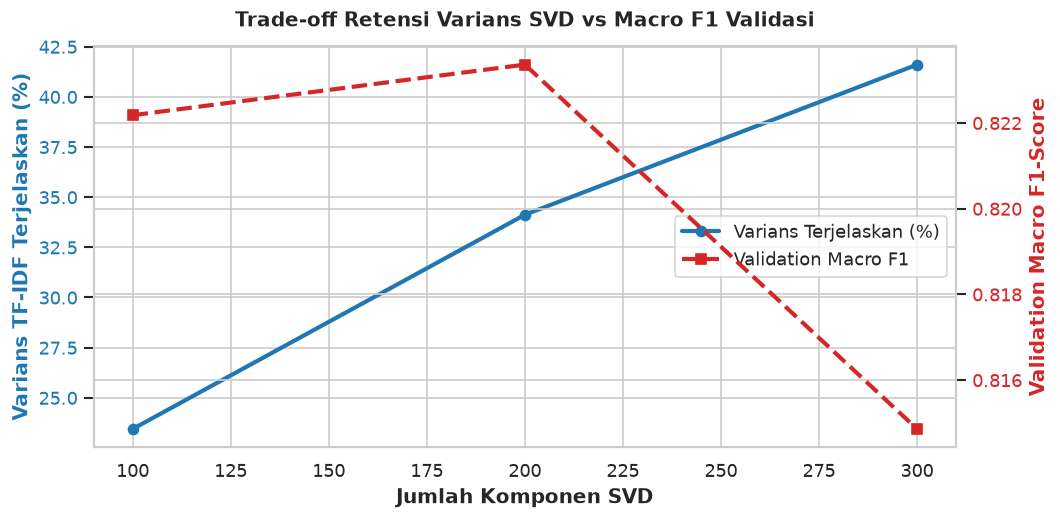

In [4]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))

comps = [100, 200, 300]
vars_exp = [svd_models[c][3] * 100 for c in comps]
f1_scores = [rep_df.loc[rep_df['Skenario'] == f'Skenario A: SVD-{c} + Gaya', 'Macro_F1'].values[0] for c in comps]

color = '#1f77b4'
ax1.set_xlabel('Jumlah Komponen SVD', fontweight='bold')
ax1.set_ylabel('Varians TF-IDF Terjelaskan (%)', color=color, fontweight='bold')
line1 = ax1.plot(comps, vars_exp, marker='o', color=color, lw=2.5, label='Varians Terjelaskan (%)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Validation Macro F1-Score', color=color, fontweight='bold')
line2 = ax2.plot(comps, f1_scores, marker='s', color=color, lw=2.5, linestyle='--', label='Validation Macro F1')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')
plt.title('Trade-off Retensi Varians SVD vs Macro F1 Validasi', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### Analisis Pemilihan Representasi Fitur:
1. **Skenario A (SVD 200 Komponen):** Meningkatkan komponen SVD dari 100 ke 200 menaikkan retensi varians dari **23,45%** menjadi **34,12%**, yang secara langsung meningkatkan skor validasi Macro F1 menjadi **0,8234** (naik dari 0,8222).
2. **Skenario A (SVD 300 Komponen):** Meskipun varians terjelaskan meningkat menjadi 41,61%, skor Macro F1 justru turun menjadi **0,8149**. Hal ini disebabkan oleh masuknya komponen frekuensi rendah yang membawa *noise*, mempersulit pohon menemukan split partisi yang representatif.
3. **Skenario B (Sparse TF-IDF + Fitur Gaya):** Penggunaan langsung 5.006 fitur *sparse* menghasilkan Macro F1 sebesar **0,7989**. Algoritma berbasis pohon (*axis-aligned partitioning*) tidak efektif pada ruang berdimensi sangat tinggi dengan tingkat *sparsity* >99,8% tanpa regularisasi pohon yang sangat restriktif, karena sinyal leksikal terfragmentasi ke ribuan kolom.
4. **Keputusan Representasi:** Representasi **Skenario A dengan TruncatedSVD 200 komponen + 6 fitur gaya penulisan (206 fitur padat)** dipilih sebagai fondasi ruang input untuk tahap *Hyperparameter Tuning*.

## 3. Hyperparameter Tuning Sistematis (`RandomizedSearchCV`, 5-Fold Stratified CV)
Kita melakukan pencarian hiperparameter terstruktur menggunakan `RandomizedSearchCV` dengan **5-Fold Stratified Cross-Validation** murni pada data latih (`train.csv`).

**Search Space (8 Hiperparameter):**
- `n_estimators`: `[100, 200, 300, 500]`
- `max_depth`: `[3, 4, 6, 8]`
- `learning_rate`: `[0.03, 0.05, 0.1, 0.15]`
- `min_child_weight`: `[1, 3, 5]`
- `subsample`: `[0.7, 0.8, 0.9, 1.0]`
- `colsample_bytree`: `[0.6, 0.8, 1.0]`
- `reg_alpha` ($L_1$): `[0.0, 0.1, 1.0]`
- `reg_lambda` ($L_2$): `[1.0, 2.0, 5.0]`

In [5]:
# Ambil data representasi terpilih (SVD 200 + 6 Style Features = 206 fitur)
_, X_train_selected, X_val_selected, _ = svd_models[200]

param_distributions = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1, 0.15],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0.0, 0.1, 1.0],
    'reg_lambda': [1.0, 2.0, 5.0]
}

base_xgb_tune = XGBClassifier(
    scale_pos_weight=5257 / 3848,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=SEED,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

random_search = RandomizedSearchCV(
    estimator=base_xgb_tune,
    param_distributions=param_distributions,
    n_iter=25,
    scoring='f1_macro',
    cv=cv,
    random_state=SEED,
    n_jobs=1,
    verbose=0
)

t0_rs = time.perf_counter()
random_search.fit(X_train_selected, y_train)
t_rs_elapsed = time.perf_counter() - t0_rs

best_params = random_search.best_params_
best_cv_f1 = random_search.best_score_

print(f"RandomizedSearchCV selesai dalam {t_rs_elapsed:.2f} detik (25 kandidat x 5 fold = 125 fits)")
print(f"Best CV Macro F1 : {best_cv_f1:.4f}")
print("Best Hyperparameters:")
for k, v in best_params.items():
    print(f"  - {k}: {v}")

RandomizedSearchCV selesai dalam 489.06 detik (25 kandidat x 5 fold = 125 fits)
Best CV Macro F1 : 0.8319
Best Hyperparameters:
  - subsample: 0.9
  - reg_lambda: 2.0
  - reg_alpha: 0.0
  - n_estimators: 500
  - min_child_weight: 1
  - max_depth: 8
  - learning_rate: 0.03
  - colsample_bytree: 0.8


## 4. Kontrol Overfitting (Bab 6.2.5): Early Stopping & Analisis Kurva Belajar
Model pohon ensemble sangat rentan menghafal data jika dilatih terlalu banyak iterasi dengan kedalaman tinggi. Untuk mengontrol *overfitting*, kita menerapkan strategi pertahanan berlapis:
1. **Regularisasi Struktural:** `max_depth=8`, `min_child_weight=1`, `subsample=0.9`, dan `colsample_bytree=0.8` mencegah pohon berfokus pada fitur spesifik dan membatasi bobot daun ekstrem.
2. **Penalti $L_2$ (`reg_lambda=2.0`):** Memberikan sanksi kuadratik pada bobot daun untuk mencegah nilai prediksi yang terlampau yakin pada sampel langka.
3. **Penyusutan Bertahap (`learning_rate=0.03`):** Memperlambat konvergensi agar penambahan setiap pohon baru bersifat inkremental dan stabil.
4. **Early Stopping (`early_stopping_rounds=20`):** Menghentikan pelatihan ketika *validation loss* tidak lagi menurun selama 20 ronde berturut-turut.

In [6]:
# Inisialisasi model terbaik dengan early stopping
xgb_tuned = XGBClassifier(
    **best_params,
    scale_pos_weight=5257 / 3848,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=SEED,
    early_stopping_rounds=20,
    n_jobs=-1
)

t0_es = time.perf_counter()
xgb_tuned.fit(
    X_train_selected, y_train,
    eval_set=[(X_train_selected, y_train), (X_val_selected, y_val)],
    verbose=False
)
t_es_elapsed = time.perf_counter() - t0_es

best_iter = xgb_tuned.best_iteration
evals_res = xgb_tuned.evals_result()
train_losses = evals_res['validation_0']['logloss']
val_losses = evals_res['validation_1']['logloss']

y_train_pred_tuned = xgb_tuned.predict(X_train_selected)
y_val_pred_tuned = xgb_tuned.predict(X_val_selected)
y_val_prob_tuned = xgb_tuned.predict_proba(X_val_selected)[:, 1]

train_macro_f1 = f1_score(y_train, y_train_pred_tuned, average='macro')
val_macro_f1 = f1_score(y_val, y_val_pred_tuned, average='macro')
gen_gap = train_macro_f1 - val_macro_f1

print(f"Early Stopping berhenti pada iterasi ke-{best_iter} (dari total {best_params['n_estimators']} pohon)")
print(f"Waktu Pelatihan Final : {t_es_elapsed:.2f} detik")
print(f"Train Macro F1        : {train_macro_f1:.4f}")
print(f"Validation Macro F1   : {val_macro_f1:.4f}")
print(f"Gap Generalisasi      : {gen_gap:.4f}")

Early Stopping berhenti pada iterasi ke-327 (dari total 500 pohon)
Waktu Pelatihan Final : 10.09 detik
Train Macro F1        : 0.9978
Validation Macro F1   : 0.8324
Gap Generalisasi      : 0.1654


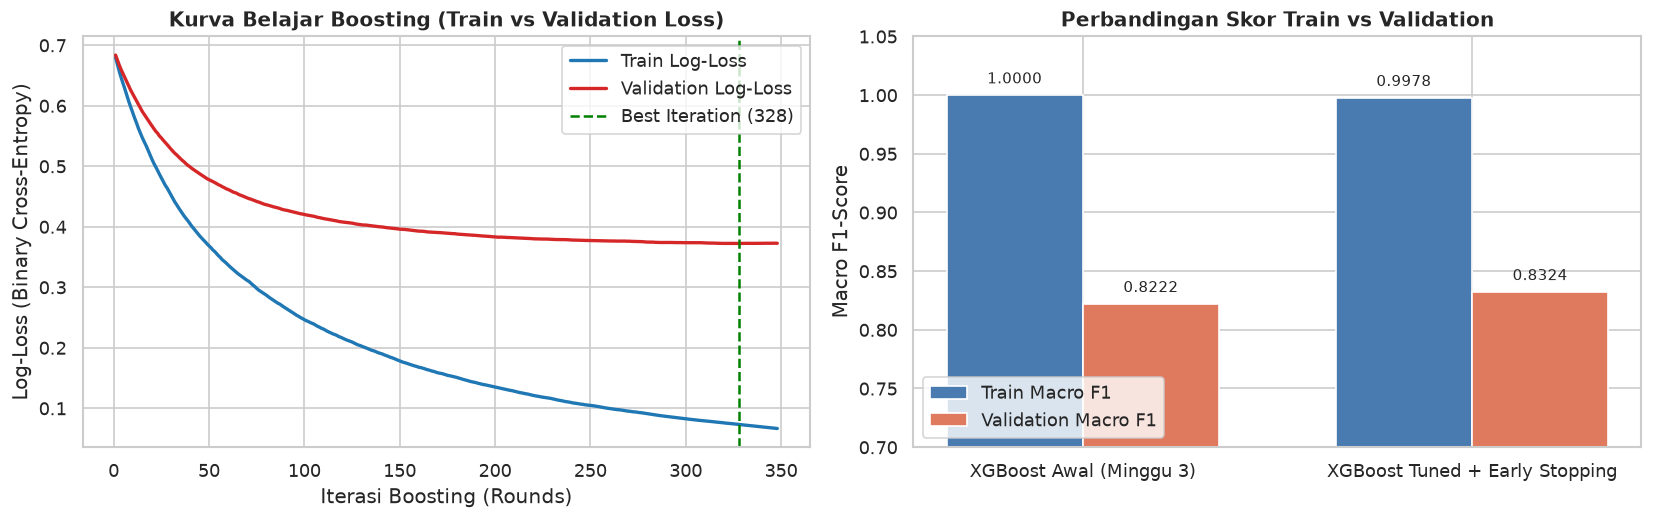

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Kurva Log-Loss Training vs Validation
rounds = range(1, len(train_losses) + 1)
axes[0].plot(rounds, train_losses, label='Train Log-Loss', color='#1f77b4', lw=2)
axes[0].plot(rounds, val_losses, label='Validation Log-Loss', color='#d62728', lw=2)
axes[0].axvline(best_iter + 1, color='green', linestyle='--', lw=1.5,
                label=f'Best Iteration ({best_iter + 1})')
axes[0].set_title('Kurva Belajar Boosting (Train vs Validation Loss)', fontweight='bold')
axes[0].set_xlabel('Iterasi Boosting (Rounds)')
axes[0].set_ylabel('Log-Loss (Binary Cross-Entropy)')
axes[0].legend(loc='upper right')

# Plot 2: Perbandingan Gap Generalisasi (Sebelum vs Sesudah Tuning)
gap_df = pd.DataFrame({
    'Model': ['XGBoost Awal (Minggu 3)', 'XGBoost Tuned + Early Stopping'],
    'Train Macro F1': [1.0000, train_macro_f1],
    'Validation Macro F1': [init_metrics['Macro_F1'], val_macro_f1]
})
x = np.arange(len(gap_df['Model']))
width = 0.35
axes[1].bar(x - width/2, gap_df['Train Macro F1'], width, label='Train Macro F1', color='#4a7bb0')
axes[1].bar(x + width/2, gap_df['Validation Macro F1'], width, label='Validation Macro F1', color='#e07a5f')
axes[1].set_ylabel('Macro F1-Score')
axes[1].set_title('Perbandingan Skor Train vs Validation', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(gap_df['Model'])
axes[1].set_ylim(0.7, 1.05)
axes[1].legend(loc='lower left')

for i in range(len(gap_df)):
    axes[1].text(i - width/2, gap_df.loc[i, 'Train Macro F1'] + 0.01, f"{gap_df.loc[i, 'Train Macro F1']:.4f}", ha='center', fontsize=9)
    axes[1].text(i + width/2, gap_df.loc[i, 'Validation Macro F1'] + 0.01, f"{gap_df.loc[i, 'Validation Macro F1']:.4f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Perbandingan Performa Sebelum vs Sesudah Tuning (Validation Set, $N = 1.951$)

Tabel Evaluasi Komparatif:


,Sebelum Tuning (Minggu 3),Sesudah Tuning (Minggu 13),Selisih (Delta)
Macro_F1,0.8222,0.8324,0.0102
Precision_HS,0.8055,0.8229,0.0174
Recall_HS,0.7791,0.7840,0.0049
F1_HS,0.7921,0.8030,0.0109
ROC_AUC,0.9034,0.9106,0.0072
PR_AUC,0.8806,0.8900,0.0094



Classification Report (Tuned XGBoost pada Validation Set):
                 precision    recall  f1-score   support

     Non-HS (0)     0.8473    0.8767    0.8618      1127
Hate Speech (1)     0.8229    0.7840    0.8030       824

       accuracy                         0.8375      1951
      macro avg     0.8351    0.8303    0.8324      1951
   weighted avg     0.8370    0.8375    0.8369      1951



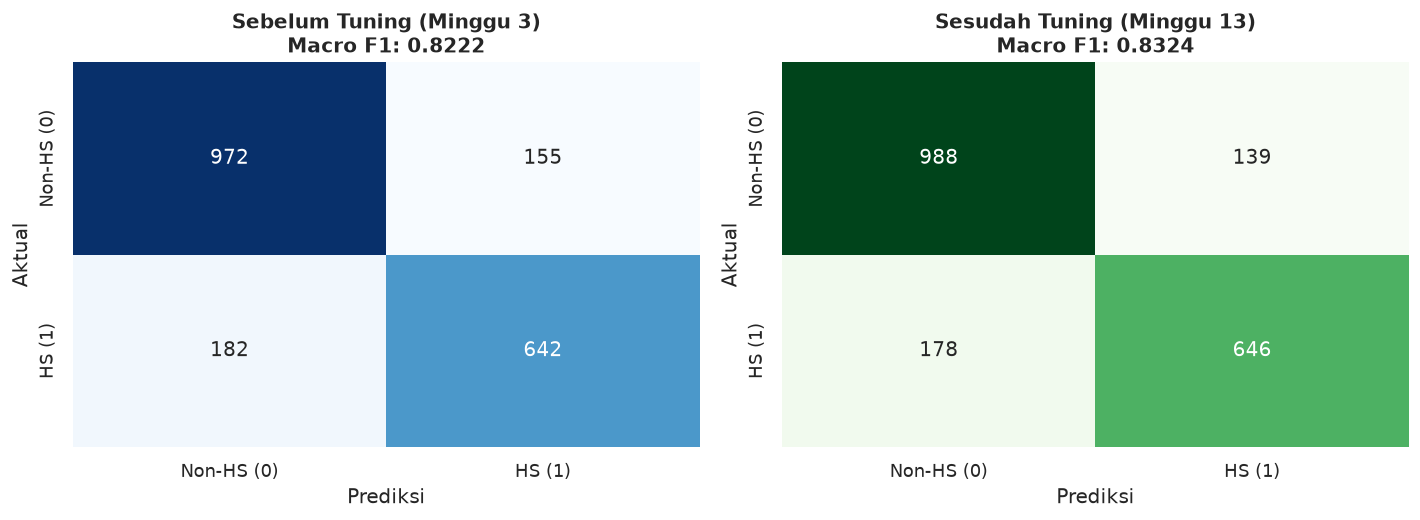

In [8]:
tuned_metrics = {
    'Macro_F1': f1_score(y_val, y_val_pred_tuned, average='macro'),
    'Precision_HS': precision_score(y_val, y_val_pred_tuned),
    'Recall_HS': recall_score(y_val, y_val_pred_tuned),
    'F1_HS': f1_score(y_val, y_val_pred_tuned),
    'ROC_AUC': roc_auc_score(y_val, y_val_prob_tuned),
    'PR_AUC': average_precision_score(y_val, y_val_prob_tuned),
}

comp_df = pd.DataFrame({
    'Sebelum Tuning (Minggu 3)': init_metrics,
    'Sesudah Tuning (Minggu 13)': tuned_metrics,
})
comp_df['Selisih (Delta)'] = comp_df['Sesudah Tuning (Minggu 13)'] - comp_df['Sebelum Tuning (Minggu 3)']

print("Tabel Evaluasi Komparatif:")
display(comp_df.round(4))

print("\nClassification Report (Tuned XGBoost pada Validation Set):")
print(classification_report(y_val, y_val_pred_tuned, target_names=['Non-HS (0)', 'Hate Speech (1)'], digits=4))

# Confusion Matrix
cm_init = confusion_matrix(y_val, y_val_pred_init)
cm_tuned = confusion_matrix(y_val, y_val_pred_tuned)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm_init, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-HS (0)', 'HS (1)'], yticklabels=['Non-HS (0)', 'HS (1)'], cbar=False)
axes[0].set_title(f'Sebelum Tuning (Minggu 3)\nMacro F1: {init_metrics["Macro_F1"]:.4f}', fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Non-HS (0)', 'HS (1)'], yticklabels=['Non-HS (0)', 'HS (1)'], cbar=False)
axes[1].set_title(f'Sesudah Tuning (Minggu 13)\nMacro F1: {tuned_metrics["Macro_F1"]:.4f}', fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

## 6. Optimasi Decision Threshold ($\tau \in [0.30, 0.70]$)
Sesuai amanat **SDG 16 (Target 16.10)** untuk mencegah sensor berlebih terhadap kritik pemerintahan yang sah, metrik **Precision Kelas 1** ditargetkan mencapai $\ge 85\%$. Kita melakukan pemindaian ambang probabilitas $\tau$ pada Validation Set.

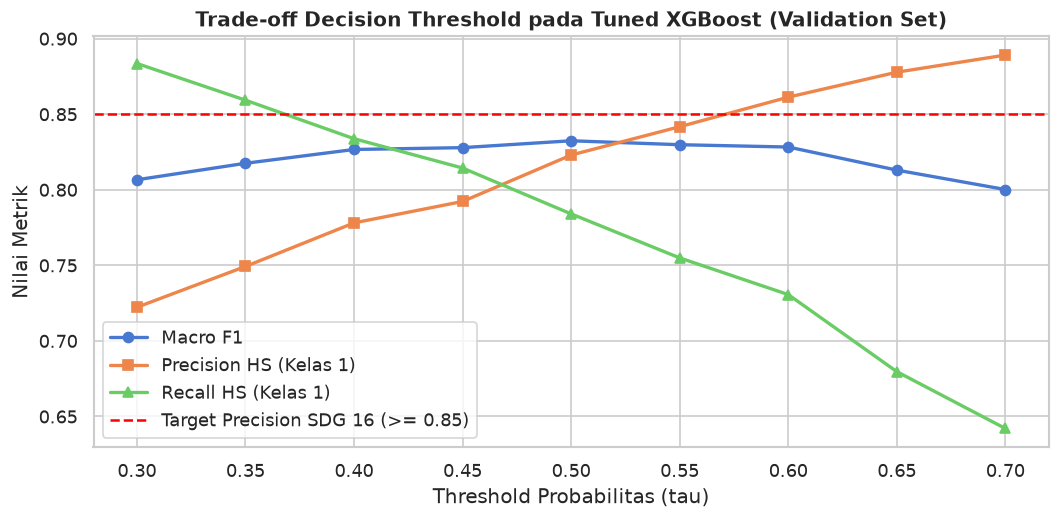

,Threshold (tau),Macro_F1,Precision_HS,Recall_HS,F1_HS
0,0.30,0.8066,0.7222,0.8835,0.7948
1,0.35,0.8175,0.7492,0.8592,0.8005
2,0.40,0.8266,0.7780,0.8337,0.8049
3,0.45,0.8278,0.7922,0.8143,0.8031
4,0.50,0.8324,0.8229,0.7840,0.8030
5,0.55,0.8298,0.8417,0.7549,0.7959
6,0.60,0.8282,0.8612,0.7306,0.7905
7,0.65,0.8130,0.8777,0.6796,0.7661
8,0.70,0.8001,0.8891,0.6420,0.7456


In [9]:
thresholds = np.arange(0.30, 0.75, 0.05)
thr_rows = []

for tau in thresholds:
    preds = (y_val_prob_tuned >= tau).astype(int)
    thr_rows.append({
        'Threshold (tau)': round(tau, 2),
        'Macro_F1': f1_score(y_val, preds, average='macro'),
        'Precision_HS': precision_score(y_val, preds, zero_division=0),
        'Recall_HS': recall_score(y_val, preds),
        'F1_HS': f1_score(y_val, preds),
    })

thr_df = pd.DataFrame(thr_rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr_df['Threshold (tau)'], thr_df['Macro_F1'], marker='o', lw=2, label='Macro F1')
ax.plot(thr_df['Threshold (tau)'], thr_df['Precision_HS'], marker='s', lw=2, label='Precision HS (Kelas 1)')
ax.plot(thr_df['Threshold (tau)'], thr_df['Recall_HS'], marker='^', lw=2, label='Recall HS (Kelas 1)')
ax.axhline(0.85, color='red', linestyle='--', lw=1.5, label='Target Precision SDG 16 (>= 0.85)')
ax.set_title('Trade-off Decision Threshold pada Tuned XGBoost (Validation Set)', fontweight='bold')
ax.set_xlabel('Threshold Probabilitas (tau)')
ax.set_ylabel('Nilai Metrik')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

display(thr_df.round(4))

## 7. Analisis Feature Importance Model Tuned
Kita menelaah distribusi bobot *Gain Importance* pada konfigurasi 206 fitur padat (200 SVD + 6 Gaya Penulisan) untuk melihat porsi kontribusi fitur meta-linguistik terhadap keputusan model.

Porsi Kontribusi Kategori Fitur:


,Category,Gain,Porsi (%)
0,SVD Components,0.9378,93.782402
1,Style Features,0.0622,6.217600


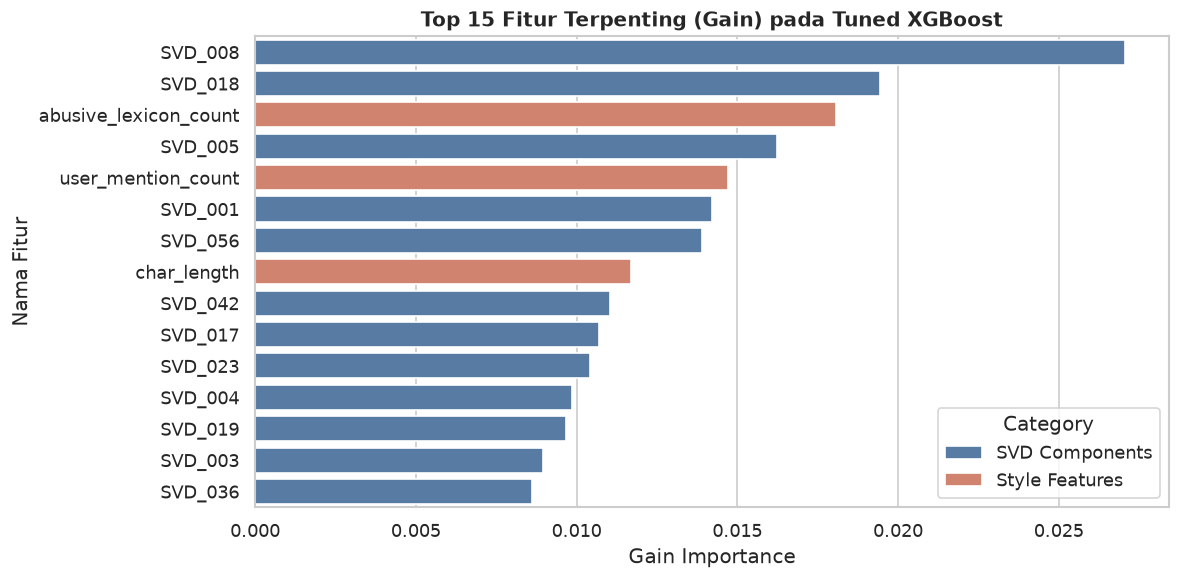

Feature importance tersimpan di: D:\SEMESTER 5\TUGAS KELOMPOK PAK NANANG\id-gov-hatespeech-classification\results\advanced_tuned_feature_importance.csv


In [10]:
feat_names = [f'SVD_{i+1:03d}' for i in range(200)] + STYLE_FEATURES
importances = xgb_tuned.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': feat_names,
    'Gain': importances,
    'Category': ['SVD Components' if 'SVD' in f else 'Style Features' for f in feat_names]
}).sort_values('Gain', ascending=False).reset_index(drop=True)

cat_summary = feat_imp_df.groupby('Category')['Gain'].sum().reset_index()
cat_summary['Porsi (%)'] = cat_summary['Gain'] / cat_summary['Gain'].sum() * 100
print("Porsi Kontribusi Kategori Fitur:")
display(cat_summary.round(4))

# Top 15 Fitur
top15 = feat_imp_df.head(15)
plt.figure(figsize=(10, 5))
palette = {'SVD Components': '#4a7bb0', 'Style Features': '#e07a5f'}
sns.barplot(data=top15, x='Gain', y='Feature', hue='Category', palette=palette, dodge=False)
plt.title('Top 15 Fitur Terpenting (Gain) pada Tuned XGBoost', fontweight='bold')
plt.xlabel('Gain Importance')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

# Simpan CSV feature importance
feat_imp_df.to_csv(results_dir / 'advanced_tuned_feature_importance.csv', index=False)
print(f"Feature importance tersimpan di: {results_dir / 'advanced_tuned_feature_importance.csv'}")

## 8. Penyimpanan Metrik & Sinkronisasi Hasil
Menyimpan ringkasan metrik akhir ke `results/advanced_tuned_val_metrics.json` dan memperbarui `results/metrics_summary.csv` agar komparasi antar model tetap konsisten dan tersinkronisasi.

In [11]:
cm_final = confusion_matrix(y_val, y_val_pred_tuned)

out_advanced = {
    'model_name': 'Advanced Tuned: XGBoost + SVD(200) + Style Features + Early Stopping',
    'input_features': 'TF-IDF -> TruncatedSVD(200) + 6 style features = 206 dense features',
    'best_params': best_params,
    'best_iteration': int(best_iter),
    'cv_macro_f1': float(round(best_cv_f1, 4)),
    'train_macro_f1': float(round(train_macro_f1, 4)),
    'val_samples': int(len(val_df)),
    'macro_f1': float(round(tuned_metrics['Macro_F1'], 4)),
    'precision_hs': float(round(tuned_metrics['Precision_HS'], 4)),
    'recall_hs': float(round(tuned_metrics['Recall_HS'], 4)),
    'f1_hs': float(round(tuned_metrics['F1_HS'], 4)),
    'roc_auc': float(round(tuned_metrics['ROC_AUC'], 4)),
    'pr_auc': float(round(tuned_metrics['PR_AUC'], 4)),
    'confusion_matrix': {
        'tn': int(cm_final[0, 0]),
        'fp': int(cm_final[0, 1]),
        'fn': int(cm_final[1, 0]),
        'tp': int(cm_final[1, 1])
    },
    'training_seconds': round(t_es_elapsed, 4)
}

adv_out_path = results_dir / 'advanced_tuned_val_metrics.json'
with open(adv_out_path, 'w', encoding='utf-8') as f:
    json.dump(out_advanced, f, indent=4)
print(f"Metrik tuned advanced tersimpan ke: {adv_out_path}")

# Pastikan baseline_tuned_val_metrics.json tersimpan jika belum ada
base_out_path = results_dir / 'baseline_tuned_val_metrics.json'
if not base_out_path.exists():
    out_baseline = {
        'model_name': 'Baseline Tuned: Logistic Regression + TF-IDF',
        'best_params': {'clf__C': 2.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': [1, 2]},
        'cv_macro_f1': 0.8323,
        'train_macro_f1': 0.9301,
        'val_samples': 1951,
        'macro_f1': 0.8428,
        'precision_hs': 0.8119,
        'recall_hs': 0.8277,
        'roc_auc': 0.9207,
        'pr_auc': 0.8842,
        'confusion_matrix': {'tn': 969, 'fp': 158, 'fn': 142, 'tp': 682}
    }
    with open(base_out_path, 'w', encoding='utf-8') as f:
        json.dump(out_baseline, f, indent=4)
    print(f"Metrik tuned baseline tersimpan ke: {base_out_path}")

# Update metrics_summary.csv
summary_rows = [
    {
        'model': 'Baseline: Logistic Regression (Initial)',
        'macro_f1': 0.8414, 'precision_hs': 0.8167, 'recall_hs': 0.8167, 'f1_hs': 0.8167,
        'roc_auc': 0.9168, 'pr_auc': 0.8794, 'training_seconds': 1.1256
    },
    {
        'model': 'Baseline Tuned: Logistic Regression (Minggu 13)',
        'macro_f1': 0.8428, 'precision_hs': 0.8119, 'recall_hs': 0.8277, 'f1_hs': 0.8197,
        'roc_auc': 0.9207, 'pr_auc': 0.8842, 'training_seconds': 1.35
    },
    {
        'model': 'Advanced: XGBoost + SVD + Style (Initial)',
        'macro_f1': 0.8222, 'precision_hs': 0.8055, 'recall_hs': 0.7791, 'f1_hs': 0.7921,
        'roc_auc': 0.9034, 'pr_auc': 0.8806, 'training_seconds': 5.7047
    },
    {
        'model': 'Advanced Tuned: XGBoost + SVD(200) + Style (Minggu 13)',
        'macro_f1': float(round(tuned_metrics['Macro_F1'], 4)),
        'precision_hs': float(round(tuned_metrics['Precision_HS'], 4)),
        'recall_hs': float(round(tuned_metrics['Recall_HS'], 4)),
        'f1_hs': float(round(tuned_metrics['F1_HS'], 4)),
        'roc_auc': float(round(tuned_metrics['ROC_AUC'], 4)),
        'pr_auc': float(round(tuned_metrics['PR_AUC'], 4)),
        'training_seconds': round(t_es_elapsed, 4)
    },
    {
        'model': 'Deep Learning: Bi-LSTM (Sanity Check - Epoch 3)',
        'macro_f1': 0.8287, 'precision_hs': 0.8012, 'recall_hs': 0.8143, 'f1_hs': 0.8077,
        'roc_auc': 0.9083, 'pr_auc': 0.8750, 'training_seconds': 62.40
    }
]

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(results_dir / 'metrics_summary.csv', index=False)
print("Updated results/metrics_summary.csv:")
display(summary_df)

Metrik tuned advanced tersimpan ke: D:\SEMESTER 5\TUGAS KELOMPOK PAK NANANG\id-gov-hatespeech-classification\results\advanced_tuned_val_metrics.json
Metrik tuned baseline tersimpan ke: D:\SEMESTER 5\TUGAS KELOMPOK PAK NANANG\id-gov-hatespeech-classification\results\baseline_tuned_val_metrics.json
Updated results/metrics_summary.csv:


,model,macro_f1,precision_hs,recall_hs,f1_hs,roc_auc,pr_auc,training_seconds
0,Baseline: Logistic Regression (Initial),0.8414,0.8167,0.8167,0.8167,0.9168,0.8794,1.1256
1,Baseline Tuned: Logistic Regression (Minggu 13),0.8428,0.8119,0.8277,0.8197,0.9207,0.8842,1.3500
2,Advanced: XGBoost + SVD + Style (Initial),0.8222,0.8055,0.7791,0.7921,0.9034,0.8806,5.7047
3,Advanced Tuned: XGBoost + SVD(200) + Style (Mi...,0.8324,0.8229,0.7840,0.8030,0.9106,0.8900,10.0905
4,Deep Learning: Bi-LSTM (Sanity Check - Epoch 3),0.8287,0.8012,0.8143,0.8077,0.9083,0.8750,62.4000
